# Практическое занятие № 16 — кластеризация заказов методом K-means
**ТюмГУ · «Технологии искусственного интеллекта — 1» · 90 минут**

**Цель:** выделить группы похожих заказов по признакам, доступным **в момент создания заказа**, сравнить несколько K, интерпретировать центроиды и проверить устойчивость.

`actual_minutes` и `late` НЕ используются для обучения K-means, выбора K и масштабирования. K-means не предсказывает «верные классы»: номера кластеров — условные. `demo_orders_13_14.csv` нужен только для проверки работоспособности.

## 1. Подготовка данных и постановка задачи (0–20 мин)
Используем три признака, доступных до доставки: `distance_km`, `queue_size`, `promised_minutes`. Стандартизация необходима из-за разных масштабов. Сохраняем хронологический holdout 20%: подбор K только на первых 80% заказов.

In [1]:
from pathlib import Path
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score,calinski_harabasz_score,davies_bouldin_score,adjusted_rand_score
from sklearn.base import clone

DATA_PATH=Path('orders_dirty.csv')
# Основная работа выполняется только на полной таблице.
assert DATA_PATH.exists(), 'Нужен orders_dirty.csv из предыдущей лабораторной работы'
if not DATA_PATH.exists(): raise FileNotFoundError('Загрузите orders_dirty.csv или демонстрационный demo_orders_13_14.csv')
print('ИСТОЧНИК:', DATA_PATH.name, '(демо — НЕ основание для выводов об исходных заказах)' if DATA_PATH.name.startswith('demo') else '')
raw=pd.read_csv(DATA_PATH,encoding='utf-8-sig')
FEATURES=['distance_km','queue_size','promised_minutes']
assert {'order_id','created_at',*FEATURES}.issubset(raw.columns)
source_size=len(raw); duplicates=int(raw.duplicated().sum())
df=raw.drop_duplicates().copy()
invalid_ids=int(df['order_id'].isna().sum())
invalid_dates=int(pd.to_datetime(df['created_at'],errors='coerce').isna().sum())
df['created_at']=pd.to_datetime(df['created_at'],errors='coerce')
df=df.dropna(subset=['order_id','created_at'])
if not df['order_id'].is_unique:
    raise ValueError('Повторные order_id с различными строками: решите конфликт ключей перед обучением!')
for c in FEATURES:
    df[c]=pd.to_numeric(df[c],errors='coerce')
    df.loc[df[c]<0,c]=np.nan
# promised_minutes — положительная длительность; ноль физически недопустим.
df.loc[df['promised_minutes']<=0,'promised_minutes']=np.nan
df=df.sort_values(['created_at','order_id'],kind='stable').reset_index(drop=True)
assert len(df)>=30,'Для этой практики нужно не менее 30 корректно датированных заказов.'
n_dev=int(len(df)*.8)
dev=df.iloc[:n_dev].copy(); holdout=df.iloc[n_dev:].copy()
assert set(dev.order_id).isdisjoint(set(holdout.order_id))
assert dev.created_at.max()<=holdout.created_at.min()
print('Строк исходно:',source_size,'полных повторов:',duplicates,'в работе:',len(df))
print('Некорректные ID / даты:',invalid_ids,invalid_dates)
print('Dev / Holdout:',len(dev),len(holdout))
print('Входы:',FEATURES,'; исходные late и actual_minutes в них отсутствуют')
print('Пропуски в dev:\n',dev[FEATURES].isna().sum())
assert {'late','actual_minutes','order_id'}.isdisjoint(FEATURES)

prep=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
               ('scale',StandardScaler())])
Z=prep.fit_transform(dev[FEATURES])  # только dev! Не holdout.
assert Z.shape==(len(dev),len(FEATURES)) and np.isfinite(Z).all()
print('Средние нормализованных признаков:',np.mean(Z,axis=0).round(3))
assert np.allclose(Z.mean(axis=0),0,atol=1e-10)
scaler=prep.named_steps['scale']; imp=prep.named_steps['impute']
scaler_table=pd.DataFrame({'feature':FEATURES,'imputer_median':imp.statistics_,
                           'dev_mean':scaler.mean_,'dev_scale':scaler.scale_})
scaler_table.to_csv('16_scaler_parameters.csv',index=False,encoding='utf-8-sig')
print('Параметры обработки, рассчитанные только на dev:\n',scaler_table.round(3).to_string(index=False))


ИСТОЧНИК: orders_dirty.csv 
Строк исходно: 600 полных повторов: 1 в работе: 599
Некорректные ID / даты: 0 0
Dev / Holdout: 479 120
Входы: ['distance_km', 'queue_size', 'promised_minutes'] ; исходные late и actual_minutes в них отсутствуют
Пропуски в dev:
 distance_km         2
queue_size          1
promised_minutes    0
dtype: int64
Средние нормализованных признаков: [-0.  0.  0.]
Параметры обработки, рассчитанные только на dev:
          feature  imputer_median  dev_mean  dev_scale
     distance_km             8.9     9.162      5.254
      queue_size             9.0    10.021      6.447
promised_minutes            51.0    50.952     14.059


## 2. K-means: алгоритм и зависимость от K (20–45 мин)
Минимизируем сумму квадратов расстояний до центроидов (inertia):  \(J=\sum_{i=1}^n\|z_i-\mu_{c_i}\|^2\). 
Каждый кандидат использует одинаковую матрицу `Z` и `random_state=42`. Silhouette максимизируем, DB минимизируем; никакой показатель не доказывает существование «естественных» групп.

 k  inertia  silhouette  calinski_harabasz  davies_bouldin
 2  802.397       0.388            377.252           1.003
 3  576.469       0.382            355.278           0.946
 4  409.204       0.394            397.685           0.838
 5  344.911       0.367            375.206           0.903
 6  292.719       0.370            369.806           0.752


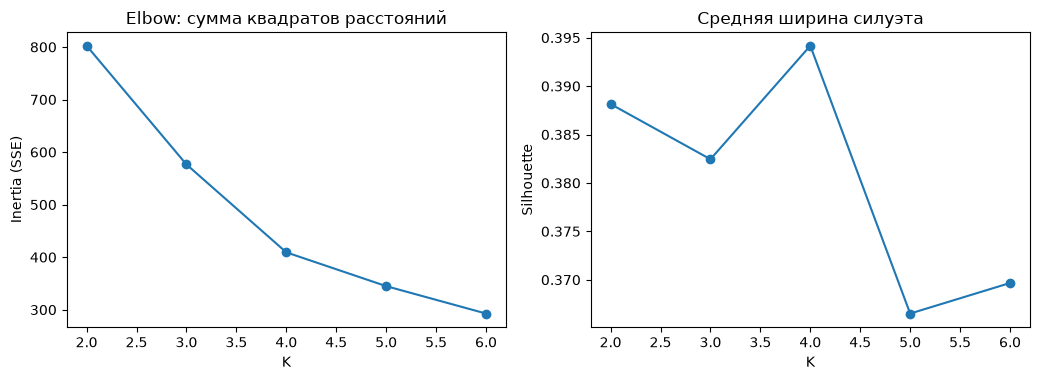

K по максимуму Silhouette: 4 (проинтерпретируйте также Elbow и бизнес-смысл)
Максимум CH: K= 4
Минимум DB: K= 6
Снижение inertia при увеличении K: [nan, -225.93, -167.26, -64.29, -52.19]


In [2]:
ks=list(range(2,min(7,len(dev)-1)))
assert len(ks)>=2
rows=[]; fitted={}
for k in ks:
    km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    lab=km.fit_predict(Z)
    rows.append({'k':k,'inertia':float(km.inertia_),
                 'silhouette':float(silhouette_score(Z,lab)),
                 'calinski_harabasz':float(calinski_harabasz_score(Z,lab)),
                 'davies_bouldin':float(davies_bouldin_score(Z,lab))})
    fitted[k]=km
scores=pd.DataFrame(rows)
print(scores.round(3).to_string(index=False))
scores.to_csv('16_k_metrics.csv',index=False,encoding='utf-8-sig')
fig,axs=plt.subplots(1,2,figsize=(10.5,3.9))
axs[0].plot(scores.k,scores.inertia,'o-');axs[0].set(xlabel='K',ylabel='Inertia (SSE)',title='Elbow: сумма квадратов расстояний')
axs[1].plot(scores.k,scores.silhouette,'o-');axs[1].set(xlabel='K',ylabel='Silhouette',title='Средняя ширина силуэта')
fig.tight_layout();fig.savefig('16_elbow_silhouette.png',dpi=160);plt.show()
# Явное учебное правило выбора, без late / actual_minutes.
chosen_k=int(scores.loc[scores.silhouette.idxmax(),'k'])
print('K по максимуму Silhouette:',chosen_k,'(проинтерпретируйте также Elbow и бизнес-смысл)')
print('Максимум CH: K=',int(scores.loc[scores.calinski_harabasz.idxmax(),'k']))
print('Минимум DB: K=',int(scores.loc[scores.davies_bouldin.idxmin(),'k']))
print('Снижение inertia при увеличении K:',scores.inertia.diff().round(2).tolist())


## 3. Устойчивость к инициализации и масштабам (45–65 мин)
Повторите обучение при разных seed и сравните разметки через Adjusted Rand Index (ARI): он устойчив к переименованию кластеров. Сравните K-means на числах без стандартизации **только как контрольный эксперимент**; SSE разных шкал нельзя сравнивать напрямую.

In [3]:
from itertools import combinations
seeds=[11,21,31,41,51]
labels_by_seed={seed:KMeans(n_clusters=chosen_k,init='k-means++',n_init=10,
                            random_state=seed).fit_predict(Z) for seed in seeds}
pairwise=pd.DataFrame([{'seed_a':a,'seed_b':b,'ARI':adjusted_rand_score(labels_by_seed[a],labels_by_seed[b])}
                       for a,b in combinations(seeds,2)])
print('Все 10 попарных ARI:\n',pairwise.round(4).to_string(index=False))
raw_imputed=prep.named_steps['impute'].transform(dev[FEATURES])
raw_labels=KMeans(n_clusters=chosen_k,init='k-means++',n_init=10,random_state=42).fit_predict(raw_imputed)
scaled_labels=fitted[chosen_k].labels_
scale_ari=float(adjusted_rand_score(raw_labels,scaled_labels))
print('ARI с масштабированием против без него:',round(scale_ari,4))
stab=pairwise.copy()
stab['comparison']='seed_pair'
stab.loc[len(stab)]={'seed_a':np.nan,'seed_b':np.nan,'ARI':scale_ari,'comparison':'scaled_vs_raw'}
stab.to_csv('16_stability.csv',index=False,encoding='utf-8-sig')
print('Попарный ARI: средний',round(pairwise.ARI.mean(),4),'; минимальный',round(pairwise.ARI.min(),4))

# Дополнительное задание: категориальный признак без использования holdout.
assert 'weather' in dev.columns
weather=dev['weather'].fillna('неизвестно').astype(str).to_frame()
ohe=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
W=ohe.fit_transform(weather)
ZW=np.column_stack([Z,W])
weather_labels=KMeans(n_clusters=chosen_k,init='k-means++',n_init=10,random_state=42).fit_predict(ZW)
weather_ari=float(adjusted_rand_score(scaled_labels,weather_labels))
weather_seeds={seed:KMeans(n_clusters=chosen_k,init='k-means++',n_init=10,random_state=seed).fit_predict(ZW)
               for seed in seeds}
weather_pairwise=[adjusted_rand_score(weather_seeds[a],weather_seeds[b]) for a,b in combinations(seeds,2)]
weather_table=pd.DataFrame({'metric':['ARI_base_vs_weather','mean_pairwise_ARI_weather','min_pairwise_ARI_weather',
                                      'numeric_columns','weather_onehot_columns'],
                            'value':[weather_ari,float(np.mean(weather_pairwise)),float(np.min(weather_pairwise)),
                                     Z.shape[1],W.shape[1]]})
weather_table.to_csv('16_weather_comparison.csv',index=False,encoding='utf-8-sig')
print('OneHot weather: ARI с базой',round(weather_ari,4),'; средний попарный ARI',round(np.mean(weather_pairwise),4))
print('Категории weather:',ohe.categories_[0].tolist())


Все 10 попарных ARI:
  seed_a  seed_b    ARI
     11      21 0.9889
     11      31 1.0000
     11      41 1.0000
     11      51 1.0000
     21      31 0.9889
     21      41 0.9889
     21      51 0.9889
     31      41 1.0000
     31      51 1.0000
     41      51 1.0000
ARI с масштабированием против без него: 0.6795
Попарный ARI: средний 0.9956 ; минимальный 0.9889
OneHot weather: ARI с базой 0.98 ; средний попарный ARI 0.9751
Категории weather: ['clear', 'rain', 'snow', 'неизвестно']


## 4. Профили кластеров и визуализация (65–82 мин)
Центроиды переводятся обратно в исходные единицы через `inverse_transform`. График показывает только две координаты, хотя модель обучалась на трёх; точки на проекции могут перекрываться без совпадения в полном пространстве признаков. Отдельно укажите количество заказов в каждом кластере.

Размеры и средние по восстановленным признакам:
            n  distance_km  queue_size  promised_minutes
cluster                                                
0        108         6.08       16.49             48.34
1        137         4.28        5.76             34.64
2         89        15.29       16.13             70.26
3        145        12.31        5.48             56.46
Центроиды в исходных единицах:
  cluster   n  distance_km  queue_size  promised_minutes
       0 108         6.08       16.49             48.34
       1 137         4.28        5.76             34.64
       2  89        15.29       16.13             70.26
       3 145        12.31        5.48             56.46


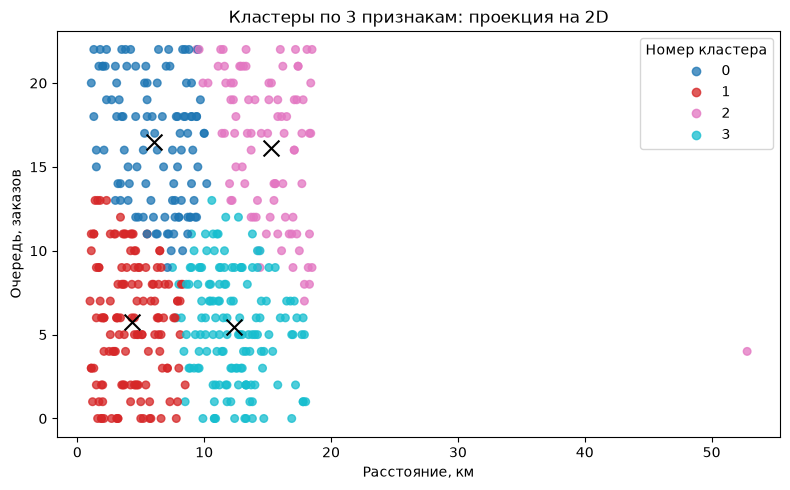

На проекции не показан третий признак — promised_minutes; все 479 точек учтены.
Holdout размечен готовой моделью; K и параметры обработки не пересчитывались: {0: 28, 1: 38, 2: 31, 3: 23}


In [4]:
km=fitted[chosen_k]
imputed_dev=pd.DataFrame(prep.named_steps['impute'].transform(dev[FEATURES]),columns=FEATURES,index=dev.index)
profiles=imputed_dev.copy()
profiles['cluster']=km.labels_
profiles['order_id']=dev.order_id.values
counts=profiles.groupby('cluster').size().rename('n')
means=profiles.groupby('cluster')[FEATURES].mean()
centers=pd.DataFrame(prep.named_steps['scale'].inverse_transform(km.cluster_centers_),columns=FEATURES)
centers.insert(0,'cluster',np.arange(chosen_k))
centers.insert(1,'n',centers.cluster.map(counts))
print('Размеры и средние по восстановленным признакам:\n',pd.concat([counts,means],axis=1).round(2).to_string())
print('Центроиды в исходных единицах:\n',centers.round(2).to_string(index=False))
centers.to_csv('16_centroids.csv',index=False,encoding='utf-8-sig')
profiles.to_csv('16_cluster_assignments_dev.csv',index=False,encoding='utf-8-sig')
fig,ax=plt.subplots(figsize=(8,5))
scatter=ax.scatter(imputed_dev['distance_km'],imputed_dev['queue_size'],c=km.labels_,cmap='tab10',s=30,alpha=.76)
ax.scatter(centers.distance_km,centers.queue_size,c='black',marker='x',s=130,label='Центроиды')
ax.set(xlabel='Расстояние, км',ylabel='Очередь, заказов',title='Кластеры по 3 признакам: проекция на 2D')
ax.legend(*scatter.legend_elements(),title='Номер кластера',loc='best')
fig.tight_layout();fig.savefig('16_clusters_projection.png',dpi=160);plt.show()
print('На проекции не показан третий признак — promised_minutes; все',len(dev),'точек учтены.')
Z_holdout=prep.transform(holdout[FEATURES])
assert np.isfinite(Z_holdout).all()
held_labels=km.predict(Z_holdout)
pd.DataFrame({'order_id':holdout.order_id.values,'cluster':held_labels}).to_csv('16_cluster_assignments_holdout.csv',index=False,encoding='utf-8-sig')
print('Holdout размечен готовой моделью; K и параметры обработки не пересчитывались:',pd.Series(held_labels).value_counts().sort_index().to_dict())


## 5. Отчёт и самостоятельная работа (82–90 мин)
1. Дайте смысловое название каждому кластеру по **трём признакам** и его размеру. Не называйте группы «плохими» или «хорошими» без внешней проверки.
2. Покажите Elbow, Silhouette, CH, DB и обоснуйте свой K. Перечислите по одной ситуации, когда каждый индекс вводит в заблуждение.
3. Объясните, почему стандартизация влияет на расстояния и распределение кластеров; приведите ARI.
4. Объясните, почему результаты K-means не являются доказательством причин задержек или готовой сегментацией клиентов.
5. Дополнительная часть: добавьте категориальный `weather` через OneHotEncoder, сопоставьте устойчивость; обязательно обсудите изменение весов блоков признаков.

**Сдать:** `Группа_Фамилия_З16_Отчет.pdf` (или DOCX) + `16_student.ipynb` + таблицы `16_k_metrics.csv`, `16_centroids.csv`, `16_stability.csv`. Блокнот должен работать после Restart & Run All.

## Ответы на вопросы самостоятельной работы

1. **Названия и размеры кластеров.** Профили рассчитаны на 479 заказах dev. Средние значения совпадают с центроидами после обратного преобразования и округления.

   | Кластер | Смысловое название | Заказов | Расстояние, км | Очередь, заказов | Обещано, мин |
   |---:|---|---:|---:|---:|---:|
   | 0 | Близкие, большая очередь, средний срок | 108 | 6,08 | 16,49 | 48,34 |
   | 1 | Близкие, малая очередь, короткий срок | 137 | 4,28 | 5,76 | 34,64 |
   | 2 | Далёкие, большая очередь, длинный срок | 89 | 15,29 | 16,13 | 70,26 |
   | 3 | Далёкие, малая очередь, средне длинный срок | 145 | 12,31 | 5,48 | 56,46 |

   Эти названия описывают условия заказа. «Хорошими» и «плохими» группы назвать нельзя без внешней проверки результата доставки; номера кластеров условны.

2. **Выбор K.** Для K=4 Silhouette достигает максимума 0,394, CH — максимума 397,685. На Elbow после K=4 снижение inertia замедляется: 167,26 при переходе 3→4 и 64,29 при 4→5. DB=0,838 при K=4; минимум DB=0,752 достигается при K=6, однако четыре сегмента имеют более ясную предметную трактовку. Поэтому выбрано K=4. Elbow может не показывать явного излома при плавном снижении inertia; Silhouette может пропустить группы сложной формы; CH может предпочесть излишнее дробление; DB чувствителен к разбросу и близости центров. Ни один индекс не служит единственным основанием для выбора.

3. **Влияние стандартизации.** Без неё признаки с большим численным разбросом сильнее влияют на евклидовы расстояния и состав групп. После стандартизации три числовых признака сопоставимы. ARI разбиений с масштабированием и без него — **0,6795**, то есть группы заметно меняются. Сравнивать абсолютные inertia разных шкал нельзя. Для пяти seed при выбранном K средний попарный ARI — 0,9956, минимум — 0,9889; все десять значений приведены в `16_stability.csv`.

4. **Границы интерпретации.** K-means группирует заказы по признакам, известным при их создании, и не устанавливает причин задержек. `actual_minutes` и `late` в обучении и выборе K не использовались. Кластеры описывают заказы, а не клиентов и их повторяющееся поведение. Временной holdout из 120 заказов только размечен готовой моделью: размеры групп 28, 38, 31 и 23.

5. **Добавление `weather`.** OneHotEncoder, обученный только на dev, добавил четыре бинарных столбца к трём стандартизованным числовым признакам. ARI разбиения с погодой и базового разбиения — **0,9800**; средний попарный ARI пяти запусков с погодой — 0,9751 против 0,9956 без неё. Смена категории погоды даёт вклад 2 в квадрат евклидова расстояния, а сдвиг одного стандартизованного числового признака на одно стандартное отклонение — вклад 1. Поэтому вес погодного блока следует задавать осмысленно: простое добавление четырёх столбцов не делает блоки равновесными. Пропуски погоды выделены в категорию «неизвестно».
